In [ ]:

# Lab Exercise 4: ARIMA Model Implementation

# Step 1: Import the required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller

from sklearn.metrics import mean_absolute_error, mean_squared_error

print("All libraries imported successfully!")


All libraries imported successfully!


In [ ]:

# Step 2: Load the dataset
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"

df = pd.read_csv(url)

# Convert Month into datetime format
df["Month"] = pd.to_datetime(df["Month"])

# Set Month as the index
df = df.set_index("Month")

# Extract the passenger series
series = df["Passengers"].astype(float)

# Display the first five rows
print(df.head())

# Display dataset information
print("\nDataset shape:", df.shape)
print("\nDataset information:")
print(df.info())

            Passengers
Month                 
1949-01-01         112
1949-02-01         118
1949-03-01         132
1949-04-01         129
1949-05-01         121

Dataset shape: (144, 1)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 144 entries, 1949-01-01 to 1960-12-01
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Passengers  144 non-null    int64
dtypes: int64(1)
memory usage: 2.2 KB
None


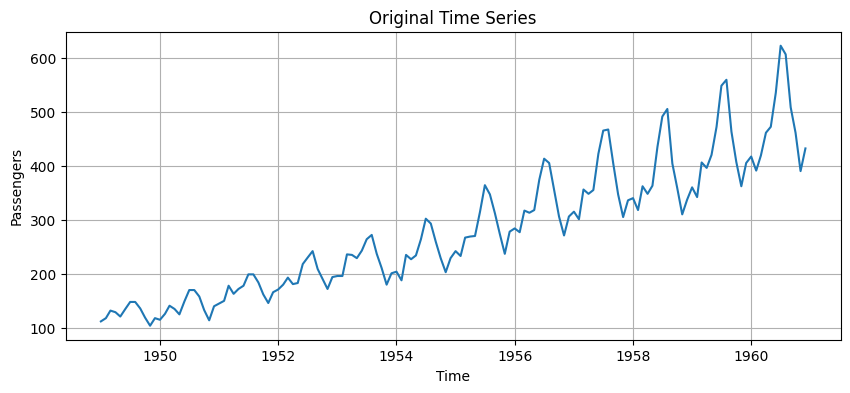

In [ ]:
# 4. Plot the original time series
plt.figure(figsize=(10, 4))
plt.plot(series)
plt.title("Original Time Series")
plt.xlabel("Time")
plt.ylabel("Passengers")
plt.grid()
plt.show()


In [ ]:
# 5. Test stationarity using the Augmented Dickey-Fuller test
adf_result = adfuller(series)
print("ADF statistic:", adf_result[0])
print("p-value:", adf_result[1])


ADF statistic: 0.8153688792060498
p-value: 0.991880243437641


/tmp/ipykernel_1336/2064668709.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(series)


In [ ]:
# 6. First-order differencing
diff_series = series.diff().dropna()

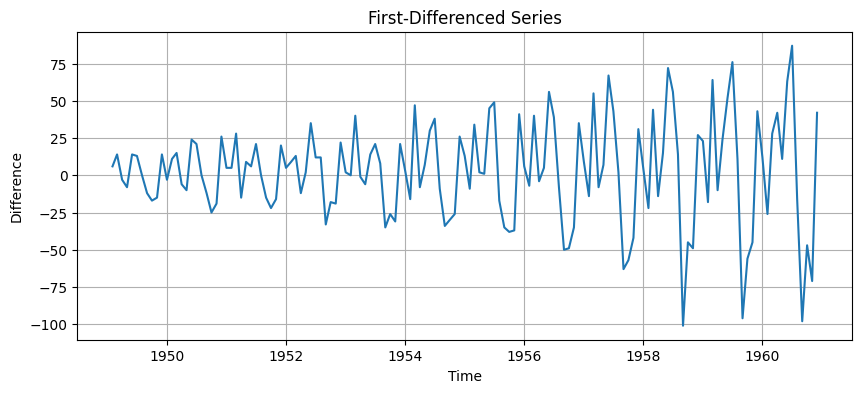

In [ ]:
# 7. Plot the differenced series
plt.figure(figsize=(10, 4))
plt.plot(diff_series)
plt.title("First-Differenced Series")
plt.xlabel("Time")
plt.ylabel("Difference")
plt.grid()
plt.show()

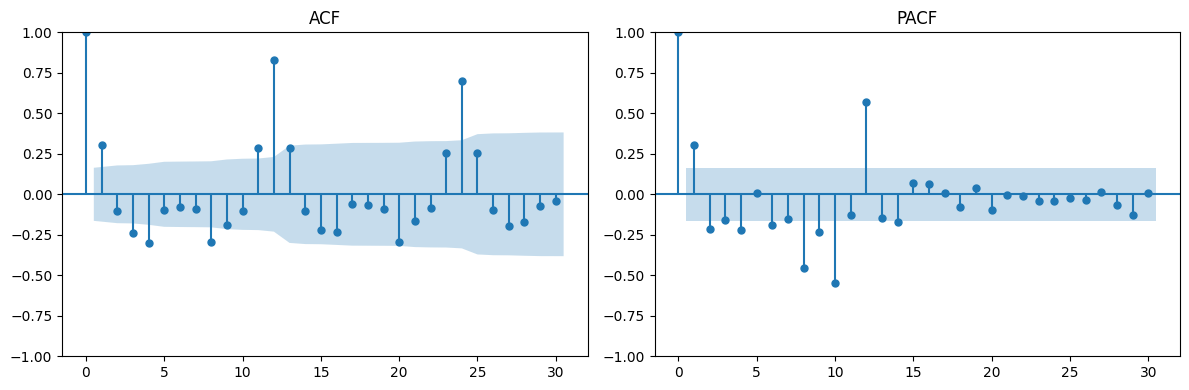

In [ ]:
# 8. Plot ACF and PACF of the differenced series
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(diff_series, ax=axes[0], lags=30)
plot_pacf(diff_series, ax=axes[1], lags=30, method="ywm")
axes[0].set_title("ACF")
axes[1].set_title("PACF")
plt.tight_layout()
plt.show()

In [ ]:
# 9. Create train-test split
train_size = int(len(series) * 0.80)
train = series.iloc[:train_size]
test = series.iloc[train_size:]

In [ ]:
# 10. Fit an ARIMA model
model = ARIMA(train, order=(2, 1, 2))
model_fit = model.fit()

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [ ]:
# 11. Display the model summary
print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:             Passengers   No. Observations:                  115
Model:                 ARIMA(2, 1, 2)   Log Likelihood                -523.758
Date:                Fri, 23 Oct 2026   AIC                           1057.516
Time:                        15:52:11   BIC                           1071.197
Sample:                    01-01-1949   HQIC                          1063.069
                         - 07-01-1958                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.3280      0.145      2.268      0.023       0.045       0.611
ar.L2          0.2521      0.165      1.528      0.126      -0.071       0.575
ma.L1         -0.0125      0.109     -0.114      0.9

In [ ]:
# 12. Forecast exactly as many steps as the test set
forecast = model_fit.forecast(steps=len(test))

In [ ]:
# 13. Calculate error metrics
mae = mean_absolute_error(test, forecast)
rmse = np.sqrt(mean_squared_error(test, forecast))

print("MAE :", mae)
print("RMSE:", rmse)

MAE : 63.54531127532635
RMSE: 82.51301130378361


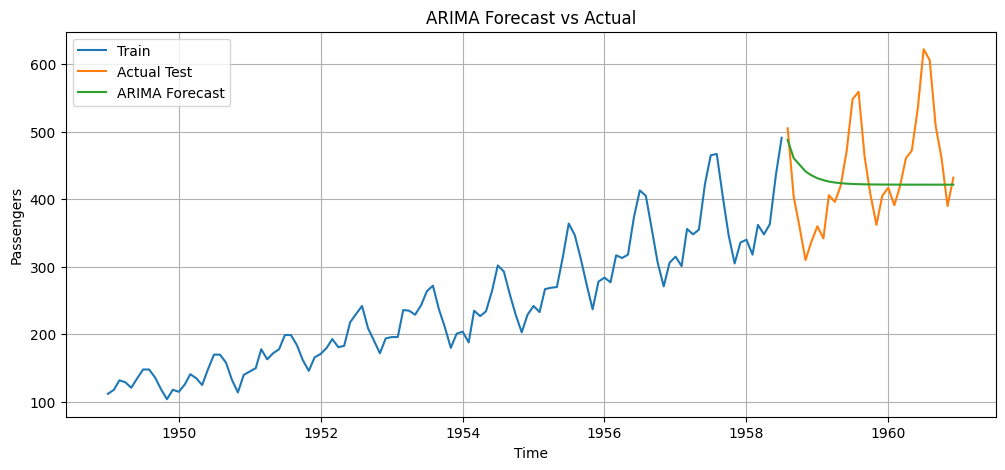

In [ ]:
# 14. Plot actual values and forecasts
plt.figure(figsize=(12, 5))
plt.plot(train.index, train, label="Train")
plt.plot(test.index, test, label="Actual Test")
plt.plot(test.index, forecast, label="ARIMA Forecast")
plt.title("ARIMA Forecast vs Actual")
plt.xlabel("Time")
plt.ylabel("Passengers")
plt.legend()
plt.grid()
plt.show()

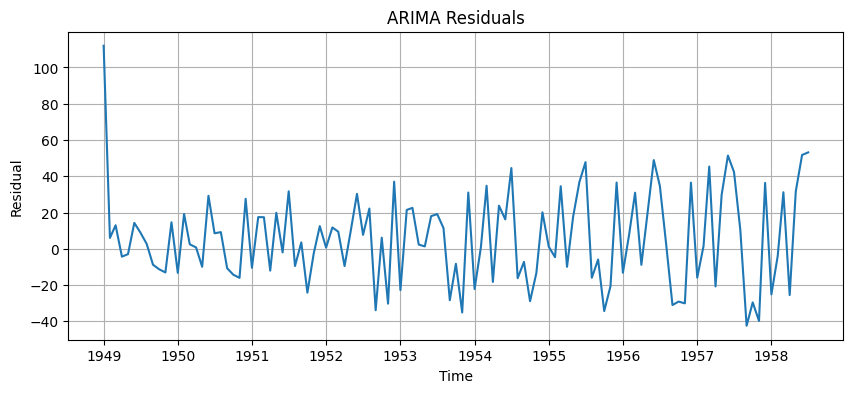

In [ ]:
# 15. Plot residuals
residuals = model_fit.resid

plt.figure(figsize=(10, 4))
plt.plot(residuals)
plt.title("ARIMA Residuals")
plt.xlabel("Time")
plt.ylabel("Residual")
plt.grid()
plt.show()

In [ ]:
#Task 4.1

# Task 4.1: Compare four ARIMA models

orders = [
    (1, 1, 1),
    (2, 1, 1),
    (1, 1, 2),
    (2, 1, 2)
]

results = []

for order in orders:
    try:
        fitted_model = ARIMA(train, order=order).fit()
        predictions = fitted_model.forecast(steps=len(test))

        mae_value = mean_absolute_error(test, predictions)
        rmse_value = np.sqrt(mean_squared_error(test, predictions))

        results.append({
            "ARIMA Order": str(order),
            "AIC": fitted_model.aic,
            "MAE": mae_value,
            "RMSE": rmse_value
        })

    except Exception as e:
        print("Model failed:", order, e)

results_df = pd.DataFrame(results)
print(results_df.round(3).to_string(index=False))

best_model_row = results_df.loc[results_df["RMSE"].idxmin()]
print("\nLowest-RMSE model:", best_model_row["ARIMA Order"])

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_date

ARIMA Order      AIC    MAE   RMSE
  (1, 1, 1) 1058.246 85.254 97.500
  (2, 1, 1) 1058.648 60.529 82.621
  (1, 1, 2) 1057.328 62.063 82.636
  (2, 1, 2) 1057.516 63.545 82.513

Lowest-RMSE model: (2, 1, 2)


#interpretation
Four ARIMA configurations were compared using the same training and testing sets. AIC was used to compare model fit while accounting for model complexity, whereas MAE and RMSE measured forecasting errors on the test data. A lower AIC indicates a preferable fit-complexity trade-off among comparable models, while lower MAE and RMSE indicate better test forecasting performance. The model with the lowest RMSE produced the smallest root-mean-squared prediction error among the tested configurations. The selected model should also be checked for residual autocorrelation before it is considered adequate.

In [ ]:
#Task 4.2

# Task 4.2: Compare d=0 and d=1
d_results = []

for order in [(2, 0, 2), (2, 1, 2)]:
    try:
        fitted_model = ARIMA(train, order=order).fit()
        predictions = fitted_model.forecast(steps=len(test))

        d_results.append({
            "Order": str(order),
            "AIC": fitted_model.aic,
            "MAE": mean_absolute_error(test, predictions),
            "RMSE": np.sqrt(mean_squared_error(test, predictions))
        })

    except Exception as e:
        print("Model failed:", order, e)

print(pd.DataFrame(d_results).round(3).to_string(index=False))

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros 

    Order      AIC    MAE    RMSE
(2, 0, 2) 1074.541 92.241 114.887
(2, 1, 2) 1057.516 63.545  82.513


When \(d=0\), the original series is modelled without non-seasonal differencing. If the series is non-stationary, its changing mean or trend may violate the assumptions of a standard ARIMA model and result in poor forecasts. When \(d=1\), first-order differencing can reduce the trend and help stabilize the series. Comparing AIC, MAE, and RMSE helps assess the effect of differencing, although differencing should also be justified by stationarity diagnostics. More differencing is not always better, because excessive differencing can remove useful information.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


 Forecast Horizon    MAE   RMSE
                6 77.787 85.581
               12 64.982 76.775
               24 62.103 79.919


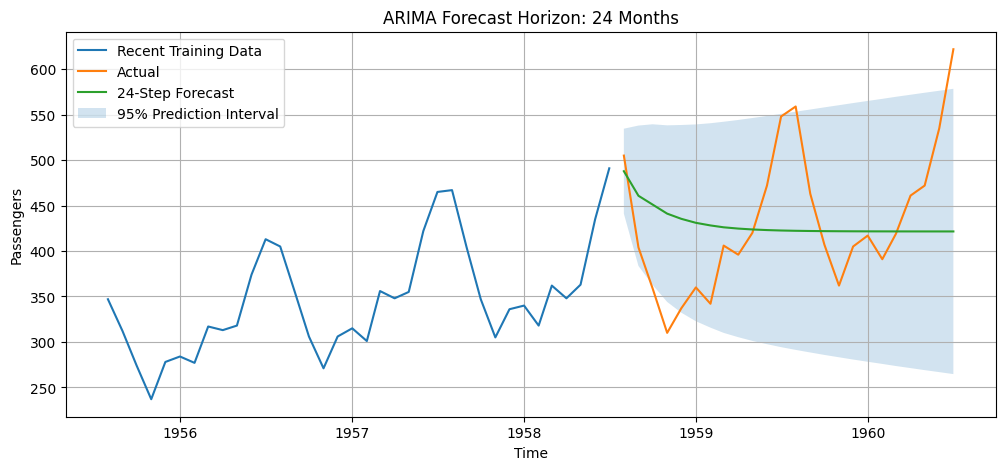

In [ ]:
#task 4.3

# Task 4.3: Forecast different horizons
horizons = [6, 12, 24]

horizon_results = []

horizon_model = ARIMA(train, order=(2, 1, 2)).fit()

for h in horizons:
    predictions = horizon_model.forecast(steps=h)
    actual = test.iloc[:h]

    horizon_results.append({
        "Forecast Horizon": h,
        "MAE": mean_absolute_error(actual, predictions),
        "RMSE": np.sqrt(mean_squared_error(actual, predictions))
    })

print(pd.DataFrame(horizon_results).round(3).to_string(index=False))

# Plot the 24-step forecast
forecast_24 = horizon_model.get_forecast(steps=24)
forecast_mean = forecast_24.predicted_mean
forecast_ci = forecast_24.conf_int()

plt.figure(figsize=(12, 5))
plt.plot(train.index[-36:], train.iloc[-36:], label="Recent Training Data")
plt.plot(test.index[:24], test.iloc[:24], label="Actual")
plt.plot(forecast_mean.index, forecast_mean, label="24-Step Forecast")
plt.fill_between(
    forecast_ci.index,
    forecast_ci.iloc[:, 0],
    forecast_ci.iloc[:, 1],
    alpha=0.2,
    label="95% Prediction Interval"
)
plt.title("ARIMA Forecast Horizon: 24 Months")
plt.xlabel("Time")
plt.ylabel("Passengers")
plt.legend()
plt.grid()
plt.show()

A forecast horizon represents the number of future time steps being predicted. In this experiment, 6, 12, and 24 steps correspond to 6, 12, and 24 months because the data are monthly. Longer forecasts generally involve greater uncertainty because prediction errors can accumulate over time. The prediction interval illustrates the uncertainty associated with the forecast, while MAE and RMSE show the actual error for each evaluated horizon. The error values may not increase monotonically, because the actual observations and seasonal patterns also affect accuracy.

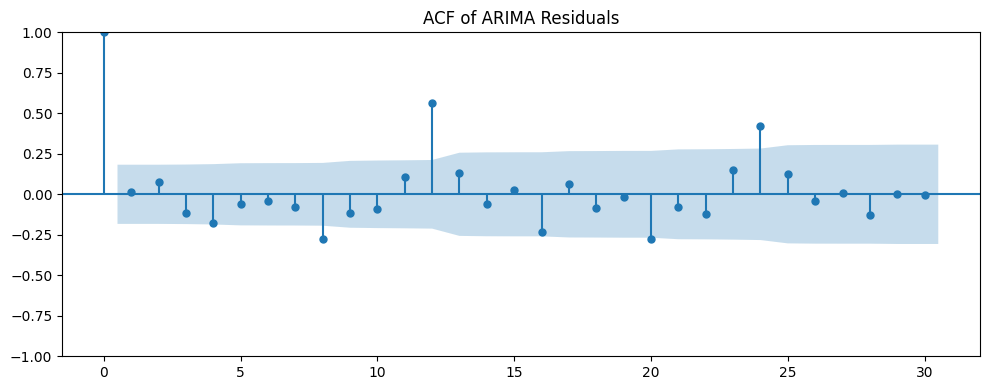

In [ ]:
# Task 4.4: Residual autocorrelation
residuals = model_fit.resid

fig, ax = plt.subplots(figsize=(10, 4))
plot_acf(residuals, ax=ax, lags=30)
ax.set_title("ACF of ARIMA Residuals")
plt.tight_layout()
plt.show()

The residual ACF is used to determine whether the fitted model has left systematic correlations unexplained. If most spikes lie within the confidence bands, there is limited evidence of residual autocorrelation at those lags. Several significant spikes suggest that the model has not captured all the time-dependent structure. Because AirPassengers has annual seasonality, remaining autocorrelation may indicate that a seasonal model would be more suitable. The conclusion should be based on the actual residual ACF generated by the experiment

Dataset: Sunspots
Source: statsmodels built-in Sunspots dataset
Frequency: Annual
Total observations: 309


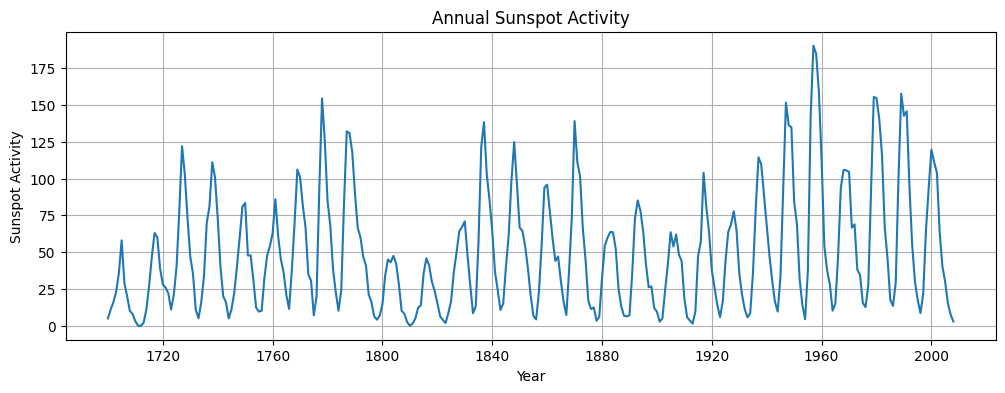

/tmp/ipykernel_1336/2897603150.py:32: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_sun = adfuller(sunspot_series)


Original ADF statistic: -2.8377807249381943
Original ADF p-value: 0.053076421728120673


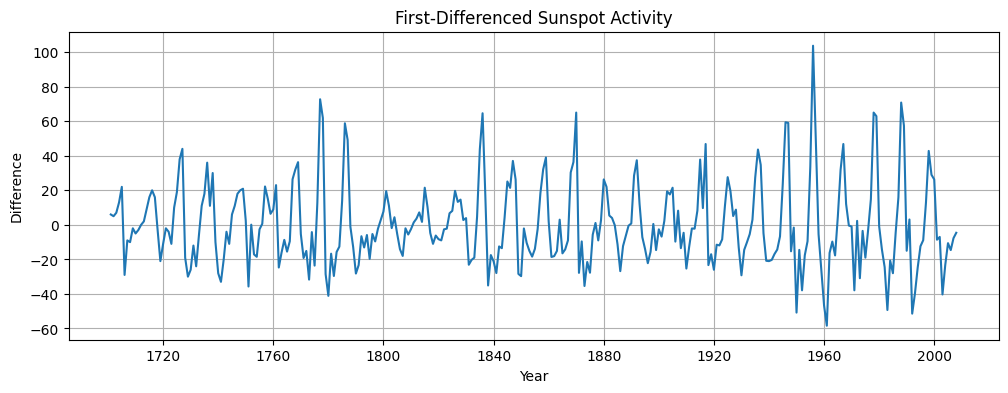

/tmp/ipykernel_1336/2897603150.py:47: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print("Differenced ADF p-value:", adfuller(sunspot_diff)[1])


Differenced ADF p-value: 1.715552423167157e-27


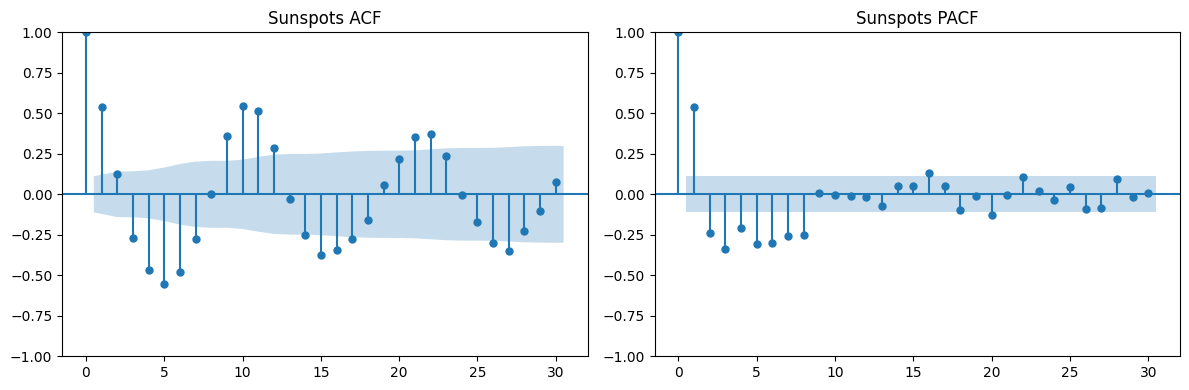

Training observations: 247
Testing observations: 62


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


                               SARIMAX Results                                
Dep. Variable:       Sunspot Activity   No. Observations:                  247
Model:                 ARIMA(2, 1, 2)   Log Likelihood               -1005.272
Date:                Fri, 23 Oct 2026   AIC                           2020.545
Time:                        16:08:31   BIC                           2038.071
Sample:                    01-01-1700   HQIC                          2027.602
                         - 01-01-1946                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.5912      0.037     43.487      0.000       1.520       1.663
ar.L2         -0.9171      0.033    -27.842      0.000      -0.982      -0.853
ma.L1         -1.4565      0.067    -21.869      0.0

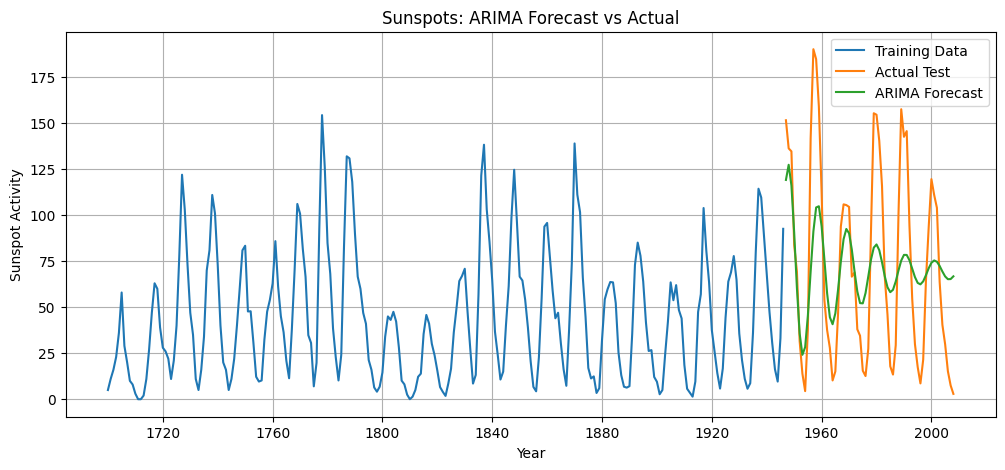

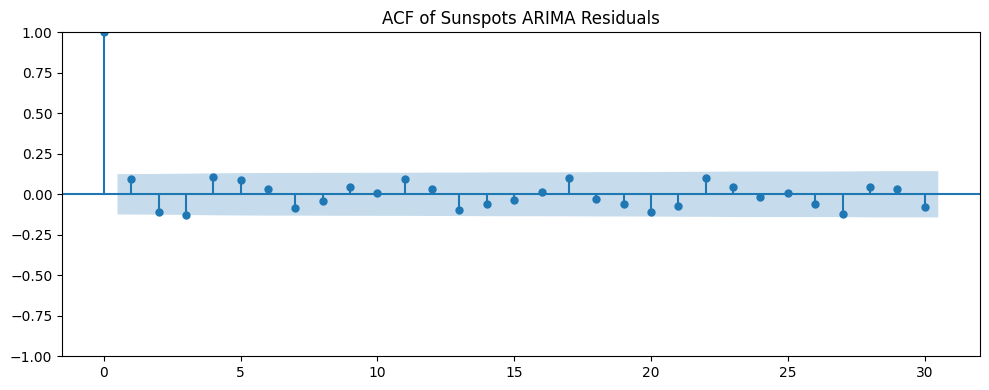

In [ ]:

# Task 4.5: ARIMA on a different real dataset

from statsmodels.datasets import sunspots

# 1. Load the Sunspots dataset
sunspot_data = sunspots.load_pandas().data

sunspot_series = pd.Series(
    sunspot_data["SUNACTIVITY"].values,
    index=pd.to_datetime(
        sunspot_data["YEAR"].astype(int).astype(str),
        format="%Y"
    ),
    name="Sunspot Activity"
).astype(float)

print("Dataset: Sunspots")
print("Source: statsmodels built-in Sunspots dataset")
print("Frequency: Annual")
print("Total observations:", len(sunspot_series))

# 2. Plot the original series
plt.figure(figsize=(12, 4))
plt.plot(sunspot_series)
plt.title("Annual Sunspot Activity")
plt.xlabel("Year")
plt.ylabel("Sunspot Activity")
plt.grid()
plt.show()

# 3. Check stationarity
adf_sun = adfuller(sunspot_series)
print("Original ADF statistic:", adf_sun[0])
print("Original ADF p-value:", adf_sun[1])

# 4. First-order differencing
sunspot_diff = sunspot_series.diff().dropna()

plt.figure(figsize=(12, 4))
plt.plot(sunspot_diff)
plt.title("First-Differenced Sunspot Activity")
plt.xlabel("Year")
plt.ylabel("Difference")
plt.grid()
plt.show()

print("Differenced ADF p-value:", adfuller(sunspot_diff)[1])

# 5. ACF and PACF
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(sunspot_diff, ax=axes[0], lags=30)
plot_pacf(sunspot_diff, ax=axes[1], lags=30, method="ywm")
axes[0].set_title("Sunspots ACF")
axes[1].set_title("Sunspots PACF")
plt.tight_layout()
plt.show()

# 6. Chronological 80/20 split
split = int(len(sunspot_series) * 0.80)
sun_train = sunspot_series.iloc[:split]
sun_test = sunspot_series.iloc[split:]

print("Training observations:", len(sun_train))
print("Testing observations:", len(sun_test))

# 7. Fit a candidate ARIMA model
sun_model = ARIMA(sun_train, order=(2, 1, 2)).fit()

print(sun_model.summary())

# 8. Forecast the test period
sun_forecast = sun_model.forecast(steps=len(sun_test))

sun_mae = mean_absolute_error(sun_test, sun_forecast)
sun_rmse = np.sqrt(mean_squared_error(sun_test, sun_forecast))

print("Selected candidate order: (2, 1, 2)")
print("AIC:", round(sun_model.aic, 3))
print("MAE:", round(sun_mae, 3))
print("RMSE:", round(sun_rmse, 3))

# 9. Plot actual versus forecast
plt.figure(figsize=(12, 5))
plt.plot(sun_train.index, sun_train, label="Training Data")
plt.plot(sun_test.index, sun_test, label="Actual Test")
plt.plot(sun_test.index, sun_forecast, label="ARIMA Forecast")
plt.title("Sunspots: ARIMA Forecast vs Actual")
plt.xlabel("Year")
plt.ylabel("Sunspot Activity")
plt.legend()
plt.grid()
plt.show()

# 10. Residual analysis
sun_residuals = sun_model.resid

fig, ax = plt.subplots(figsize=(10, 4))
plot_acf(sun_residuals, ax=ax, lags=30)
ax.set_title("ACF of Sunspots ARIMA Residuals")
plt.tight_layout()
plt.show()

The annual Sunspots dataset was selected as a second real-world univariate time series. It contains observations of sunspot activity recorded over time. The original series was plotted, and the Augmented Dickey–Fuller test was performed to assess stationarity. First-order differencing and ACF/PACF plots were used to examine the transformed series and its lag relationships. The data were split chronologically into 80% training observations and 20% testing observations. An ARIMA(2,1,2) candidate model was fitted to the training set and used to forecast the test period. MAE and RMSE were calculated to measure forecast accuracy, and the residual ACF was examined for remaining autocorrelation. The selected order is a candidate configuration and may be improved by comparing alternative orders and evaluating their performance.

Lab-05

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.metrics import mean_absolute_error, mean_squared_error


In [24]:
# 1. Load the monthly AirPassengers dataset
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
df = pd.read_csv(url)

In [25]:
# 2. Convert Month into a datetime index
df["Month"] = pd.to_datetime(df["Month"])
df = df.set_index("Month")

In [26]:
# 3. Force a monthly frequency
series = df["Passengers"].asfreq("MS").astype(float)

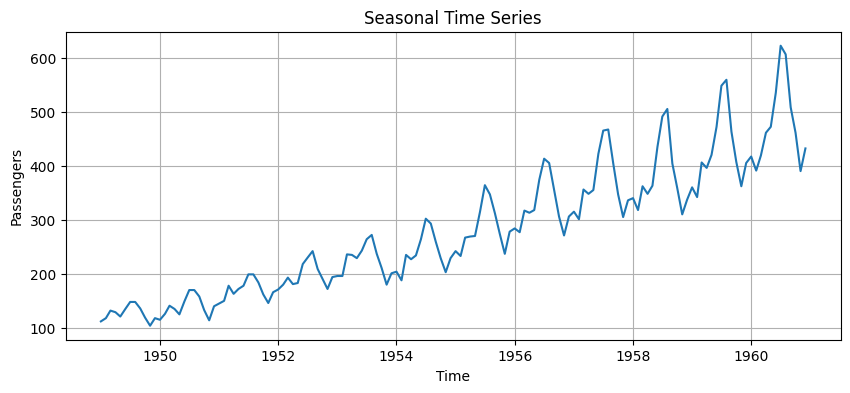

In [27]:
# 4. Plot the seasonal series
plt.figure(figsize=(10, 4))
plt.plot(series)
plt.title("Seasonal Time Series")
plt.xlabel("Time")
plt.ylabel("Passengers")
plt.grid()
plt.show()


In [28]:
# 5. Seasonal difference with s = 12
seasonal_diff = series.diff(12).dropna()

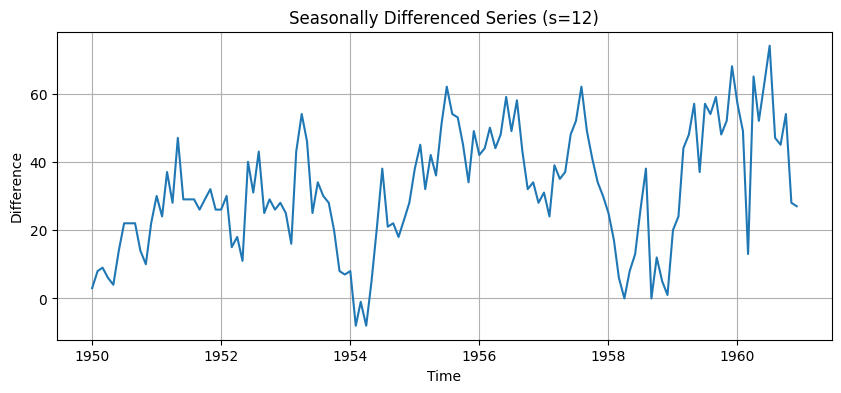

In [29]:
# 6. Plot seasonal-differenced series
plt.figure(figsize=(10, 4))
plt.plot(seasonal_diff)
plt.title("Seasonally Differenced Series (s=12)")
plt.xlabel("Time")
plt.ylabel("Difference")
plt.grid()
plt.show()

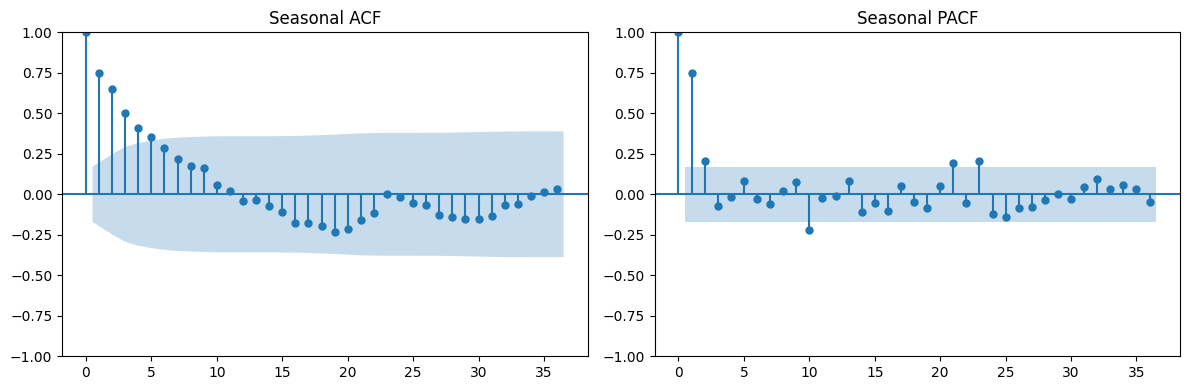

In [30]:
# 7. ACF/PACF of the transformed series
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(seasonal_diff, ax=axes[0], lags=36)
plot_pacf(seasonal_diff, ax=axes[1], lags=36, method="ywm")
axes[0].set_title("Seasonal ACF")
axes[1].set_title("Seasonal PACF")
plt.tight_layout()
plt.show()

In [31]:
# 8. Train-test split
train_size = int(len(series) * 0.80)
train = series.iloc[:train_size]
test = series.iloc[train_size:]

In [32]:
# 9. Fit SARIMA
model = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

model_fit = model.fit(disp=False)

In [33]:
# 10. Display model summary
print(model_fit.summary())

                                     SARIMAX Results                                      
Dep. Variable:                         Passengers   No. Observations:                  115
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                -323.801
Date:                            Fri, 23 Oct 2026   AIC                            657.601
Time:                                    16:26:29   BIC                            669.988
Sample:                                01-01-1949   HQIC                           662.592
                                     - 07-01-1958                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.8224      0.184     -4.461      0.000      -1.184      -0.461
ma.L1          0.7176      0.224   

In [34]:
# 11. Forecast the test period
forecast = model_fit.forecast(steps=len(test))

In [35]:
# 12. Evaluate
mae = mean_absolute_error(test, forecast)
rmse = np.sqrt(mean_squared_error(test, forecast))

print("MAE :", mae)
print("RMSE:", rmse)

MAE : 25.268045289980734
RMSE: 31.78729709859784


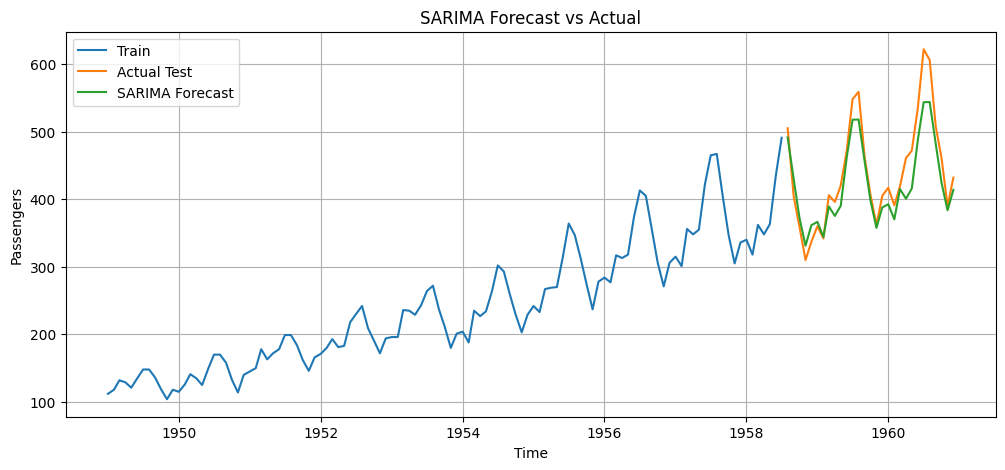

In [36]:
# 13. Plot actual and forecast
plt.figure(figsize=(12, 5))
plt.plot(train.index, train, label="Train")
plt.plot(test.index, test, label="Actual Test")
plt.plot(test.index, forecast, label="SARIMA Forecast")
plt.title("SARIMA Forecast vs Actual")
plt.xlabel("Time")
plt.ylabel("Passengers")
plt.legend()
plt.grid()
plt.show()

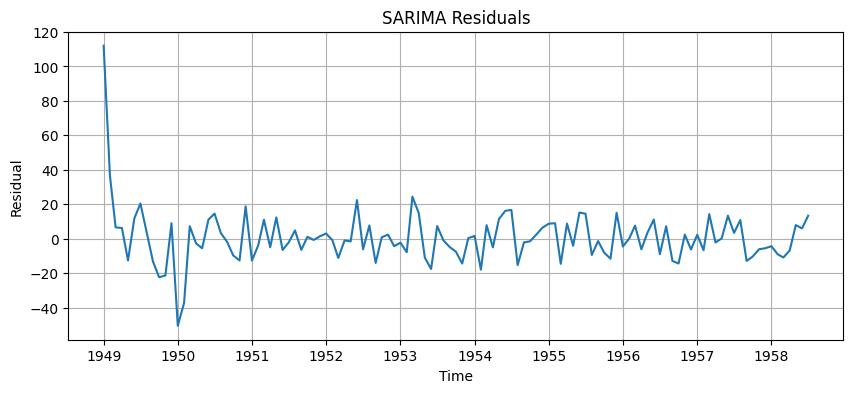

In [37]:
# 14. Residual plot
residuals = model_fit.resid

plt.figure(figsize=(10, 4))
plt.plot(residuals)
plt.title("SARIMA Residuals")
plt.xlabel("Time")
plt.ylabel("Residual")
plt.grid()
plt.show()

In [38]:
# Task 5.1: Compare three SARIMA configurations

sarima_configs = [
    ((1, 1, 1), (1, 1, 1, 12)),
    ((1, 1, 1), (0, 1, 1, 12)),
    ((2, 1, 1), (1, 1, 0, 12))
]

sarima_results = []

for order, seasonal_order in sarima_configs:
    try:
        fitted = SARIMAX(
            train,
            order=order,
            seasonal_order=seasonal_order,
            enforce_stationarity=False,
            enforce_invertibility=False
        ).fit(disp=False)

        predictions = fitted.forecast(steps=len(test))

        sarima_results.append({
            "Order": str(order),
            "Seasonal Order": str(seasonal_order),
            "AIC": fitted.aic,
            "MAE": mean_absolute_error(test, predictions),
            "RMSE": np.sqrt(mean_squared_error(test, predictions))
        })

    except Exception as e:
        print("Model failed:", order, seasonal_order, e)

sarima_results_df = pd.DataFrame(sarima_results)

print(sarima_results_df.round(3).to_string(index=False))

if not sarima_results_df.empty:
    best_idx = sarima_results_df["RMSE"].idxmin()
    print("\nLowest-RMSE configuration:")
    print(sarima_results_df.loc[best_idx])


    Order Seasonal Order     AIC    MAE   RMSE
(1, 1, 1)  (1, 1, 1, 12) 657.601 25.268 31.787
(1, 1, 1)  (0, 1, 1, 12) 659.333 23.368 29.923
(2, 1, 1)  (1, 1, 0, 12) 660.914 22.194 28.735

Lowest-RMSE configuration:
Order                 (2, 1, 1)
Seasonal Order    (1, 1, 0, 12)
AIC                  660.913752
MAE                   22.193643
RMSE                  28.734509
Name: 2, dtype: object


Three SARIMA configurations were evaluated using the same chronological train-test split. MAE and RMSE were used to compare out-of-sample forecasting accuracy, while AIC provided an additional measure of model fit and complexity. The configuration with the lowest RMSE produced the smallest root-mean-squared prediction error among the tested models. The selected model should also be checked for residual autocorrelation to determine whether systematic patterns remain. The comparison demonstrates that changing seasonal and non-seasonal orders can affect forecasting performance.

#TASK 5.2
The seasonal period \(s=12\) is appropriate for monthly data when the pattern repeats annually because each year contains 12 monthly observations. Seasonal differencing compares each month with the corresponding month in the previous year.
- Example of \(s=7\): Daily retail sales when customer activity follows a weekly pattern that repeats every seven days.
- Example of \(s=24\): Hourly electricity demand when a daily pattern repeats every 24 hours.
The seasonal period must match the sampling frequency and the repeating behaviour of the dataset. It should not be selected solely because of a convention.

Family                     Order      AIC    MAE   RMSE
 ARIMA                 (1, 1, 1) 1058.246 85.254 97.500
 ARIMA                 (2, 1, 1) 1058.648 60.529 82.621
 ARIMA                 (1, 1, 2) 1057.328 62.063 82.636
 ARIMA                 (2, 1, 2) 1057.516 63.545 82.513
SARIMA (1, 1, 1) x (1, 1, 1, 12)  657.601 25.268 31.787
SARIMA (1, 1, 1) x (0, 1, 1, 12)  659.333 23.368 29.923
SARIMA (2, 1, 1) x (1, 1, 0, 12)  660.914 22.194 28.735

Best ARIMA: (2, 1, 2)
ARIMA MAE: 63.545
ARIMA RMSE: 82.513

Best SARIMA: (2, 1, 1) x (1, 1, 0, 12)
SARIMA MAE: 22.194
SARIMA RMSE: 28.735


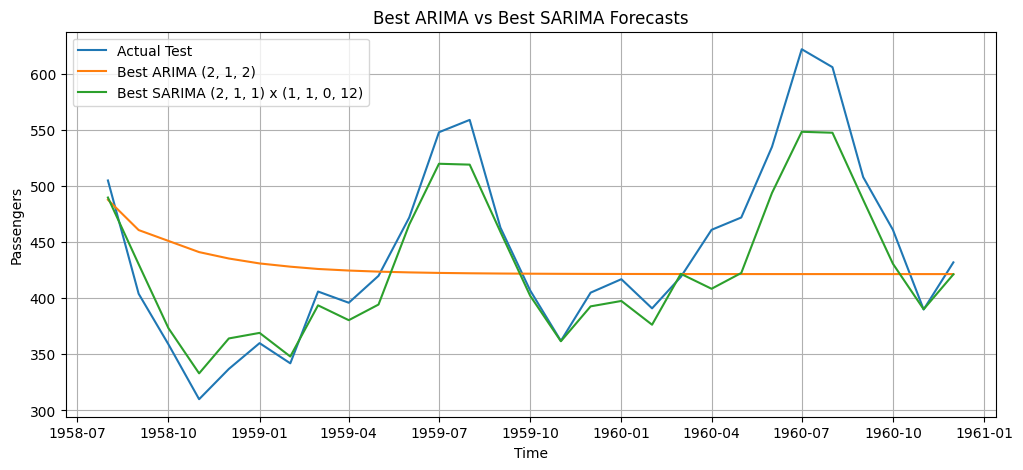

In [40]:

# Task 5.3: Compare ARIMA and SARIMA on the same test set

# ARIMA candidates from Lab 4
arima_orders = [
    (1, 1, 1),
    (2, 1, 1),
    (1, 1, 2),
    (2, 1, 2)
]

arima_comparison = []

for order in arima_orders:
    fitted = ARIMA(train, order=order).fit()
    pred = fitted.forecast(steps=len(test))

    arima_comparison.append({
        "Family": "ARIMA",
        "Order": str(order),
        "AIC": fitted.aic,
        "MAE": mean_absolute_error(test, pred),
        "RMSE": np.sqrt(mean_squared_error(test, pred)),
        "Forecast": pred
    })

# SARIMA candidates from Task 5.1
sarima_comparison = []

for order, seasonal_order in sarima_configs:
    fitted = SARIMAX(
        train,
        order=order,
        seasonal_order=seasonal_order,
        enforce_stationarity=False,
        enforce_invertibility=False
    ).fit(disp=False)

    pred = fitted.forecast(steps=len(test))

    sarima_comparison.append({
        "Family": "SARIMA",
        "Order": f"{order} x {seasonal_order}",
        "AIC": fitted.aic,
        "MAE": mean_absolute_error(test, pred),
        "RMSE": np.sqrt(mean_squared_error(test, pred)),
        "Forecast": pred
    })

# Combine model results
all_models = arima_comparison + sarima_comparison

comparison_table = pd.DataFrame([
    {k: v for k, v in item.items() if k != "Forecast"}
    for item in all_models
])

print(comparison_table.round(3).to_string(index=False))

# Select the best model within each family by RMSE
best_arima = min(
    [m for m in all_models if m["Family"] == "ARIMA"],
    key=lambda m: m["RMSE"]
)

best_sarima = min(
    [m for m in all_models if m["Family"] == "SARIMA"],
    key=lambda m: m["RMSE"]
)

print("\nBest ARIMA:", best_arima["Order"])
print("ARIMA MAE:", round(best_arima["MAE"], 3))
print("ARIMA RMSE:", round(best_arima["RMSE"], 3))

print("\nBest SARIMA:", best_sarima["Order"])
print("SARIMA MAE:", round(best_sarima["MAE"], 3))
print("SARIMA RMSE:", round(best_sarima["RMSE"], 3))

# Plot the best forecasts
plt.figure(figsize=(12, 5))
plt.plot(test.index, test, label="Actual Test")
plt.plot(
    test.index, best_arima["Forecast"],
    label=f'Best ARIMA {best_arima["Order"]}'
)
plt.plot(
    test.index, best_sarima["Forecast"],
    label=f'Best SARIMA {best_sarima["Order"]}'
)
plt.title("Best ARIMA vs Best SARIMA Forecasts")
plt.xlabel("Time")
plt.ylabel("Passengers")
plt.legend()
plt.grid()
plt.show()


The best ARIMA and SARIMA configurations were evaluated using the same training and testing observations. Their MAE and RMSE values were compared to assess forecasting accuracy. The ARIMA model represents non-seasonal time-series behaviour, whereas SARIMA additionally models recurring seasonal patterns. The model with the lower RMSE achieved better test performance among the two selected configurations. If SARIMA has lower error, this suggests that explicitly modelling seasonality helped for this dataset. If ARIMA performs better, the result should be reported as observed, because a more complex seasonal model is not guaranteed to outperform every simpler model.

 Seasonal D     AIC    MAE   RMSE
          0 721.684 18.697 22.399
          1 657.601 25.268 31.787


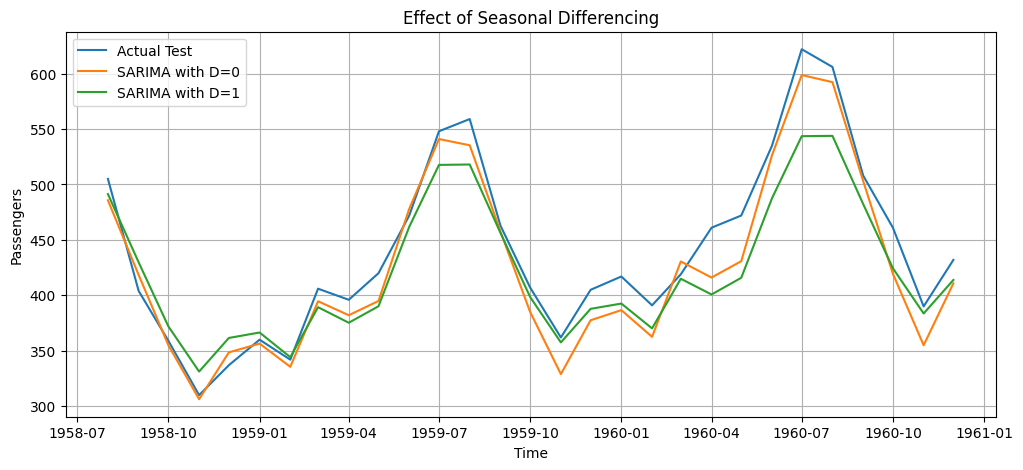

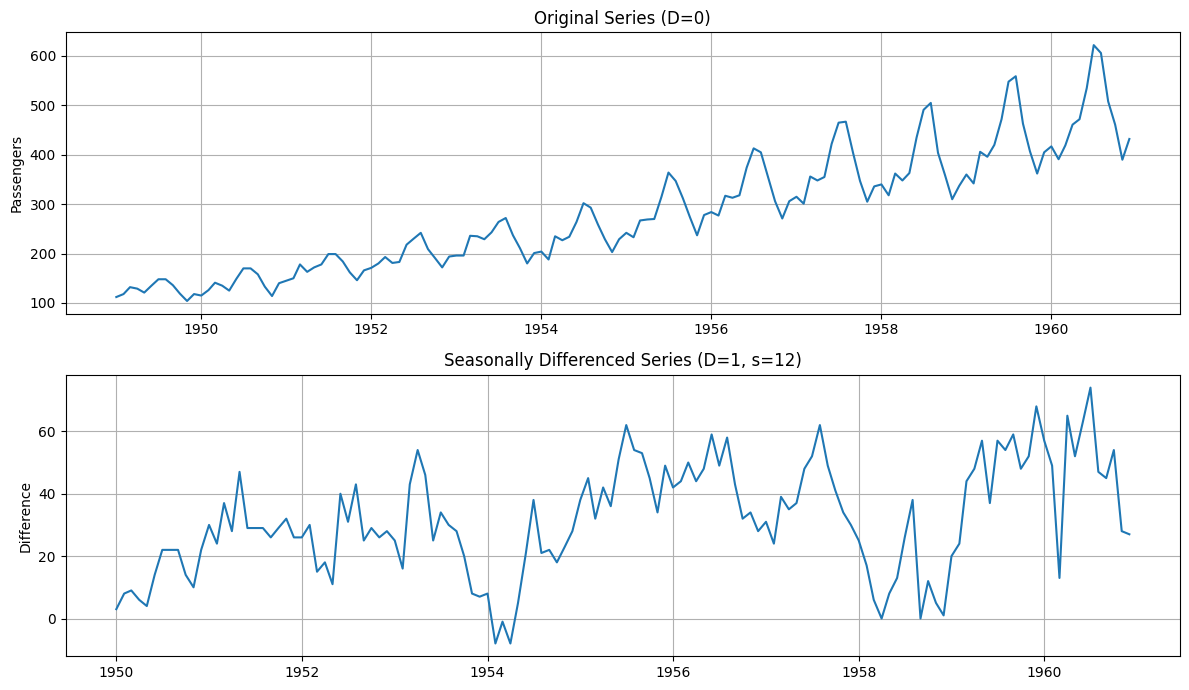

In [41]:

# Task 5.4: Compare D=0 and D=1

d_results = []
d_forecasts = {}

for D_value in [0, 1]:
    fitted = SARIMAX(
        train,
        order=(1, 1, 1),
        seasonal_order=(1, D_value, 1, 12),
        enforce_stationarity=False,
        enforce_invertibility=False
    ).fit(disp=False)

    pred = fitted.forecast(steps=len(test))
    d_forecasts[D_value] = pred

    d_results.append({
        "Seasonal D": D_value,
        "AIC": fitted.aic,
        "MAE": mean_absolute_error(test, pred),
        "RMSE": np.sqrt(mean_squared_error(test, pred))
    })

print(pd.DataFrame(d_results).round(3).to_string(index=False))

# Plot the two forecasts against actual observations
plt.figure(figsize=(12, 5))
plt.plot(test.index, test, label="Actual Test")
plt.plot(test.index, d_forecasts[0], label="SARIMA with D=0")
plt.plot(test.index, d_forecasts[1], label="SARIMA with D=1")
plt.title("Effect of Seasonal Differencing")
plt.xlabel("Time")
plt.ylabel("Passengers")
plt.legend()
plt.grid()
plt.show()

# Plot the original series with D=0 and the seasonally differenced
# series with D=1 to illustrate the transformation itself.
fig, axes = plt.subplots(2, 1, figsize=(12, 7))

axes[0].plot(series)
axes[0].set_title("Original Series (D=0)")
axes[0].set_ylabel("Passengers")
axes[0].grid()

axes[1].plot(series.diff(12).dropna())
axes[1].set_title("Seasonally Differenced Series (D=1, s=12)")
axes[1].set_ylabel("Difference")
axes[1].grid()

plt.tight_layout()
plt.show()

Seasonal differencing removes the difference between observations separated by one seasonal period. In this experiment, \(D=0\) means that no seasonal difference is applied within the SARIMA model, whereas \(D=1\) applies one seasonal difference with a period of 12 months. Seasonal differencing can reduce recurring annual patterns and help stabilize the series. The two configurations were evaluated using the same test observations, and their MAE and RMSE values were compared. Lower errors indicate better test forecasting performance for the corresponding configuration. The forecast plots and differenced-series plots help explain how seasonal differencing affects the model. The better configuration should be selected based on the observed metrics and residual diagnostics rather than assuming that \(D=1\) is always superior.

Dataset: Mauna Loa atmospheric CO2
Source: statsmodels built-in CO2 dataset
Frequency: Monthly averages
Total observations: 526
Date range: 1958-03-01 00:00:00 to 2001-12-01 00:00:00


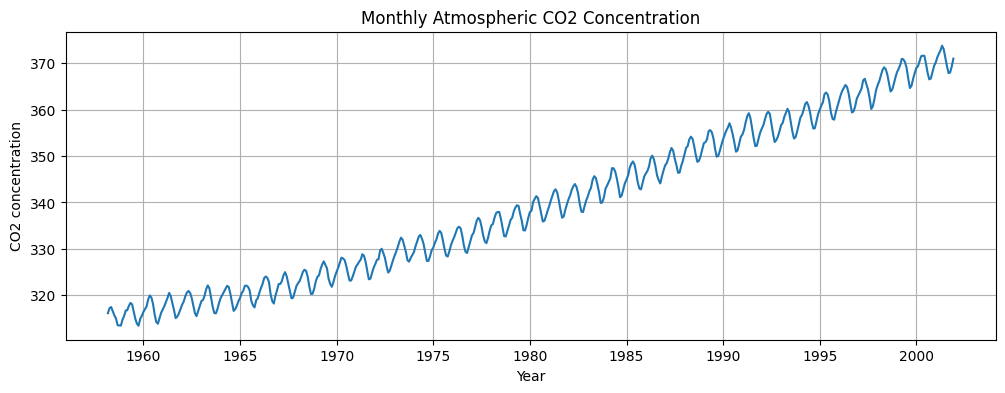

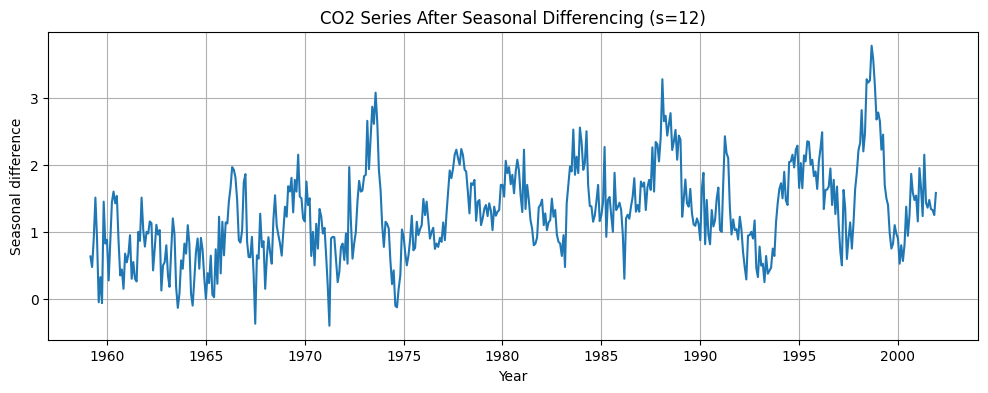

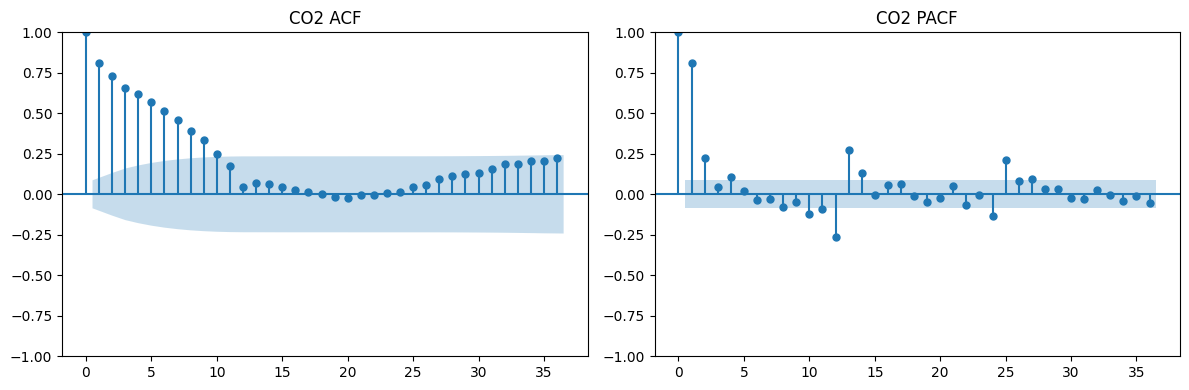

Training observations: 420
Testing observations: 106
                                     SARIMAX Results                                      
Dep. Variable:                                CO2   No. Observations:                  420
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                 -85.986
Date:                            Fri, 23 Oct 2026   AIC                            181.972
Time:                                    16:30:44   BIC                            201.841
Sample:                                03-01-1958   HQIC                           189.846
                                     - 02-01-1993                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2525      0.118      2.133      0.033       

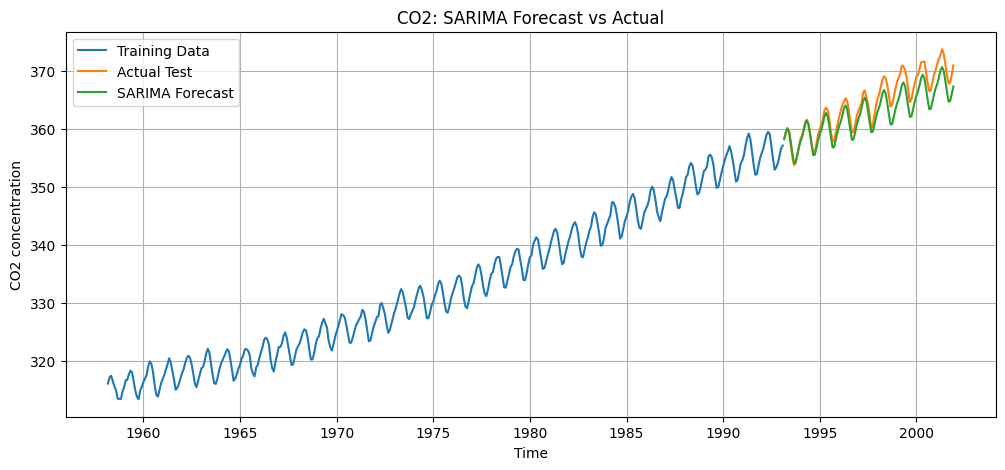

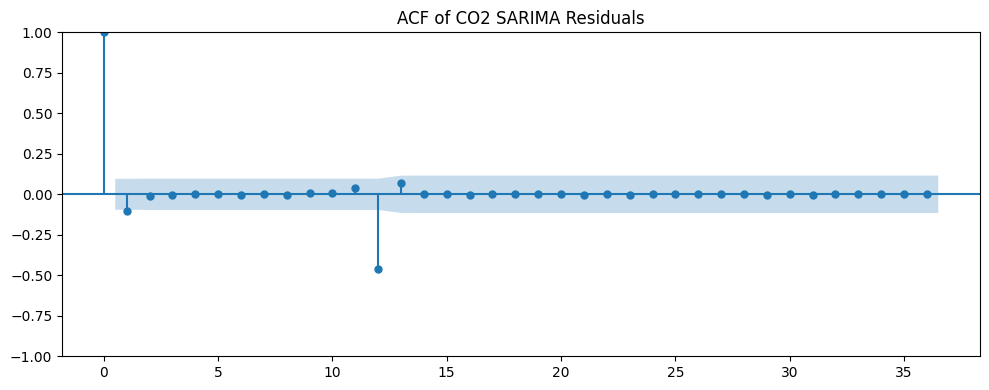

In [42]:

# Task 5.5: SARIMA on a different real seasonal dataset

from statsmodels.datasets import co2

# 1. Load the CO2 dataset
co2_data = co2.load_pandas().data

# Convert weekly observations into monthly averages.
# Interpolate missing monthly values if any occur.
co2_series = (
    co2_data["co2"]
    .resample("MS")
    .mean()
    .interpolate(method="time")
)

co2_series.name = "CO2"

print("Dataset: Mauna Loa atmospheric CO2")
print("Source: statsmodels built-in CO2 dataset")
print("Frequency: Monthly averages")
print("Total observations:", len(co2_series))
print("Date range:", co2_series.index.min(), "to", co2_series.index.max())

# 2. Plot the original series
plt.figure(figsize=(12, 4))
plt.plot(co2_series)
plt.title("Monthly Atmospheric CO2 Concentration")
plt.xlabel("Year")
plt.ylabel("CO2 concentration")
plt.grid()
plt.show()

# 3. Seasonal differencing with s=12
co2_seasonal_diff = co2_series.diff(12).dropna()

plt.figure(figsize=(12, 4))
plt.plot(co2_seasonal_diff)
plt.title("CO2 Series After Seasonal Differencing (s=12)")
plt.xlabel("Year")
plt.ylabel("Seasonal difference")
plt.grid()
plt.show()

# 4. ACF and PACF
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

plot_acf(co2_seasonal_diff, ax=axes[0], lags=36)
plot_pacf(co2_seasonal_diff, ax=axes[1], lags=36, method="ywm")

axes[0].set_title("CO2 ACF")
axes[1].set_title("CO2 PACF")

plt.tight_layout()
plt.show()

# 5. Chronological 80/20 split
split = int(len(co2_series) * 0.80)

co2_train = co2_series.iloc[:split]
co2_test = co2_series.iloc[split:]

print("Training observations:", len(co2_train))
print("Testing observations:", len(co2_test))

# 6. Fit a candidate SARIMA model
co2_model = SARIMAX(
    co2_train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

co2_fit = co2_model.fit(disp=False)

print(co2_fit.summary())

# 7. Forecast the test period
co2_forecast = co2_fit.forecast(steps=len(co2_test))

# 8. Evaluate
co2_mae = mean_absolute_error(co2_test, co2_forecast)
co2_rmse = np.sqrt(mean_squared_error(co2_test, co2_forecast))

print("Selected candidate: SARIMA(1,1,1)(1,1,1,12)")
print("AIC:", round(co2_fit.aic, 3))
print("MAE:", round(co2_mae, 3))
print("RMSE:", round(co2_rmse, 3))

# 9. Plot actual versus forecast
plt.figure(figsize=(12, 5))
plt.plot(co2_train.index, co2_train, label="Training Data")
plt.plot(co2_test.index, co2_test, label="Actual Test")
plt.plot(co2_test.index, co2_forecast, label="SARIMA Forecast")
plt.title("CO2: SARIMA Forecast vs Actual")
plt.xlabel("Time")
plt.ylabel("CO2 concentration")
plt.legend()
plt.grid()
plt.show()

# 10. Residual analysis
fig, ax = plt.subplots(figsize=(10, 4))
plot_acf(co2_fit.resid, ax=ax, lags=36)
ax.set_title("ACF of CO2 SARIMA Residuals")
plt.tight_layout()
plt.show()

The Mauna Loa atmospheric CO₂ dataset was selected as a second seasonal time series. Its observations were converted into monthly averages, and missing monthly values were interpolated using time-based interpolation. The original series and seasonally differenced series were plotted to examine their trend and recurring annual behaviour. The seasonal period was set to \(s=12\), because monthly observations with annual seasonality have twelve observations per cycle. The data were divided chronologically into training and testing sets, and a SARIMA(1,1,1)(1,1,1,12) candidate model was fitted to the training data. Forecasts were evaluated using MAE and RMSE, and the forecast graph was compared with the actual test observations. Residual autocorrelation was also examined to identify any remaining time-dependent patterns. The chosen model is a starting configuration and can be improved by comparing alternative seasonal and non-seasonal orders.